In [835]:
import pandas as pd
import numpy as np
import importlib
import ot
import numpy as np
import scipy.stats as st
import ruptures as rpt

from scipy.stats import ks_2samp

from tqdm import tqdm

import matplotlib.pyplot as plt
import seaborn as sns

import w1_tree as wt
import geotopics_plots as gtp

import plotly.express as px

import subfield_tree as sft

In [43]:
PATH = "../data_clean/"


df_country = pd.read_csv("../data/Floriana_country_info.csv").rename(columns={"alpha-2": "alpha2"})
df_topics = pd.read_csv("../data_clean/df_topics.csv")
df_topics.subfield_id = df_topics.subfield_id.astype(int)

df_cs = pd.read_csv(PATH+"df_country_subfield_roll_5y.csv", index_col=[0, 1, 2]).dropna(how="all")
df_cs.columns = df_cs.columns.astype(int)

year_list = df_cs.index.get_level_values(1).unique().sort_values().to_list()
country_list = df_cs.index.get_level_values(0).unique().sort_values().to_list()

df_prob = df_cs.div(df_cs.sum(axis=1), axis=0)

df_subfield = (
    pd.read_csv(PATH+"df_topics.csv")
    [["subfield_id", "subfield_name", "field_id", "field_name", "domain_id", "domain_name"]]
    .drop_duplicates()
    .sort_values(["domain_id", "field_id", "subfield_id"])
)
df_subfield.subfield_id = df_subfield.subfield_id.astype(int)
subfield_tree = sft.SubfieldTree(df_subfield)

df_dist_year = pd.read_csv(PATH+"df_dist_year.csv", index_col=[0, 1, 2])

In [44]:
import numpy as np

def gini(sizes, normalize=False):
    """
    Gini coefficient of cluster sizes.
    0 = all clusters equal size, higher = more unequal.

    sizes     : array-like of positive cluster sizes (e.g. [20, 15, 10, 3, 2])
    normalize : if True, multiply by K/(K-1) so the maximum possible value is 1
                regardless of the number of clusters K.
    """
    x = np.sort(np.asarray(sizes, dtype=float))   # ascending
    K = len(x)
    if K == 0 or x.sum() == 0:
        raise ValueError("sizes must be non-empty and sum to > 0")
    if K == 1:
        return 0.0

    i = np.arange(1, K + 1)
    g = (2 * np.sum(i * x)) / (K * x.sum()) - (K + 1) / K

    return g * K / (K - 1) if normalize else g


def gini_from_labels(labels, normalize=False):
    """Gini of cluster sizes directly from a label vector (one label per year)."""
    _, counts = np.unique(labels, return_counts=True)
    return gini(counts, normalize=normalize)

In [45]:
def stability_plot(country, country_name, ax, mode="individual", vmax=0, vmin=-0.5):
    year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
    

    df_plot = (
        -df_dist_year
        .xs((country, mode), level=(0, 1))
        .pivot(columns="year_to", values="distance")
    )

    inactive_years = ~df_plot.columns.isin(year_list_active)

    df_plot.loc[inactive_years, :] = None
    df_plot = df_plot.T
    df_plot.loc[inactive_years, :] = None
    # df_plot.loc[:, inactive_years] = None
    # df_plot.loc[inactive_years, inactive_years] = None
    # display(df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active"))

    dist_std = df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active").distance.std().round(2)
    dist_max = df_dist_year.xs((country, "individual"), level=(0, 1)).loc[year_list_active].query("year_to in @year_list_active").distance.max().round(2)

    hm = sns.heatmap(df_plot, ax=ax, cbar=False, cmap=cmap,)

    # cbar = hm.collections[0].colorbar
    # cbar.ax.tick_params(labelrotation=-90, labelsize=12)
    # cbar.ax.locator_params(nbins=4)

    step=6
    x_ticks = range(0, len(df_plot.columns), step)
    y_ticks = range(0, len(df_plot.index), step)

    ax.annotate(
        f"STD = {dist_std}\nMax = {dist_max}",
        xy=(48, 3),
        # xytext=(0.98, 0.35), textcoords='axes fraction',
        ha='right', va='top',
        fontsize=15, color='black',
        bbox=dict(boxstyle='round', fc='white', ec='black', alpha=0.8)
    )

    ax.set_xticks(x_ticks)
    ax.set_xticklabels(df_plot.columns[::step], rotation=45, ha="right")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(df_plot.index[::step], rotation=0)
    ax.tick_params(labelsize=16)

    ax.set_title(country_name, fontsize=18)
    # ax.tick_params(labelsize=16)
    ax.set_xlabel("")
    ax.set_ylabel("")

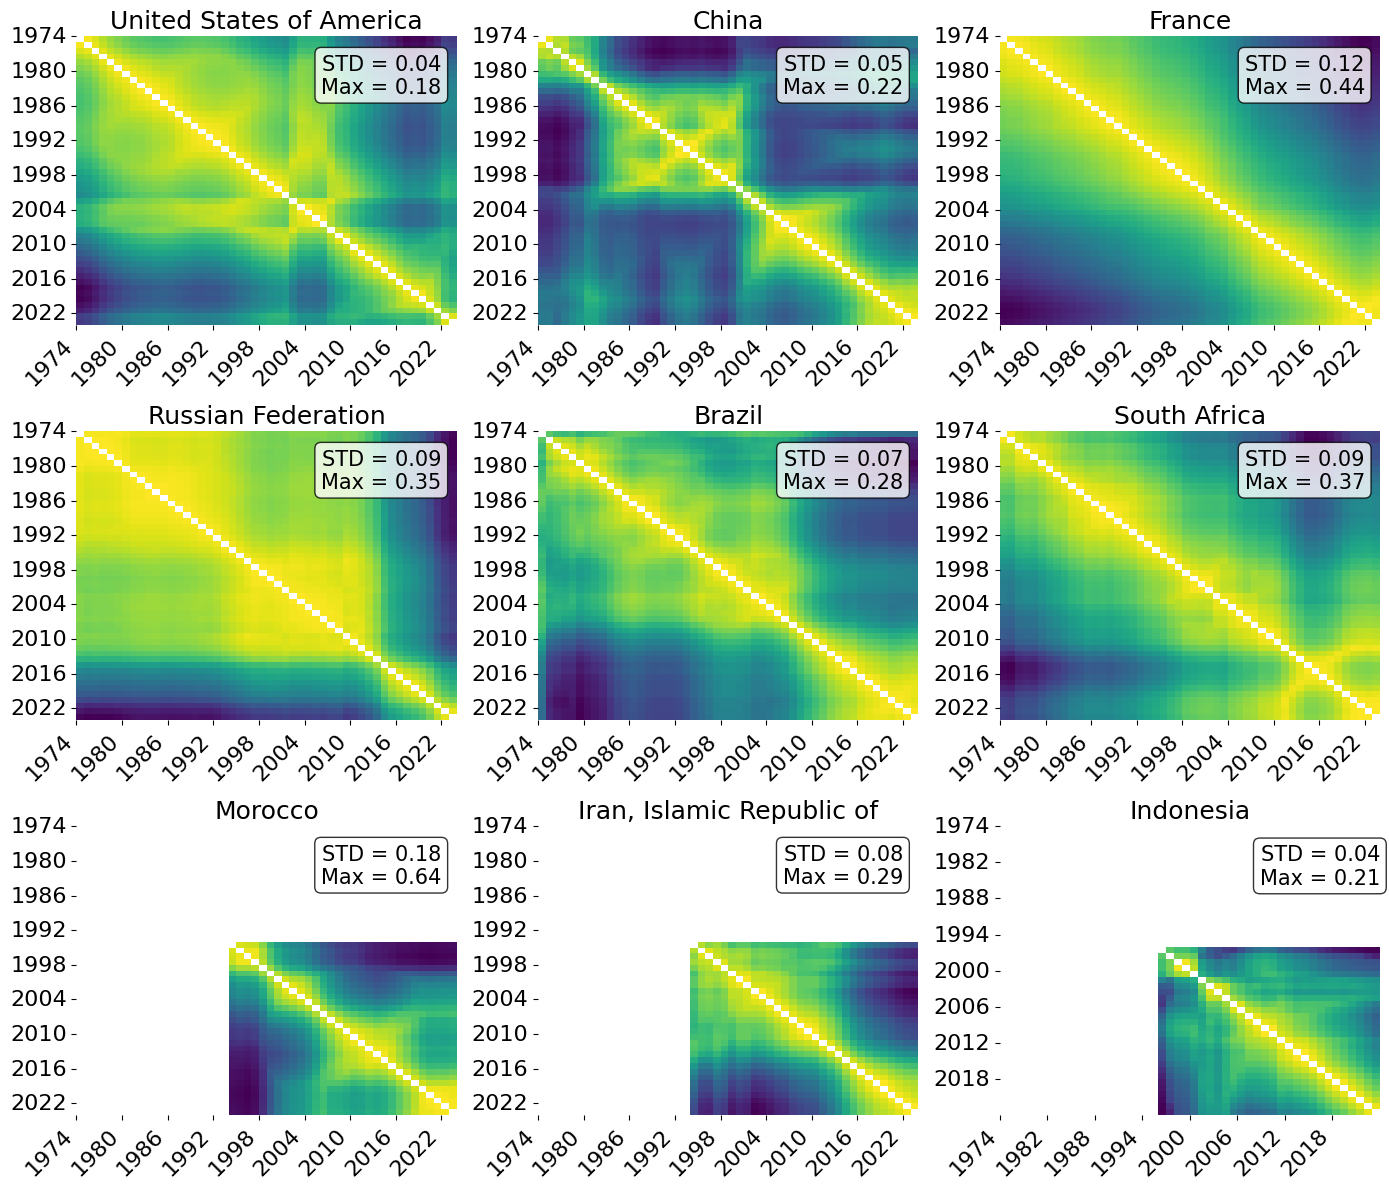

In [46]:
country_list=["US", "CN", "FR", "RU", "BR", "ZA","MA","IR","ID"]
countries = list(df_country.query("alpha2 in @country_list")[["alpha2", "name"]].set_index("alpha2").loc[country_list].to_dict()["name"].items())

cmap = "viridis"

fig, axes = plt.subplots(3, 3, figsize=(14, 12))

axes = axes.flatten()

for ax, (code, name) in zip(axes, countries):
    stability_plot(code, name, ax)

plt.tight_layout()
plt.savefig(f"../images/stability_v4.jpg", dpi=1000, bbox_inches='tight')

In [47]:
mode = "individual"

df_dist_yearly = (
    df_dist_year
    .xs((mode), level=(1))
    .loc[(country_list, slice(None)), :]
    .reset_index()
    .query("year_from == (year_to - 1)")
)

df_active_list = [] 
for country in country_list:
    year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
    # inactive_years = ~df_plot.columns.isin(year_list_active)
    df_active_list.append(
        df_dist_yearly
        .query("country == @country")
        .query("(year_to in @year_list_active) and (year_from in @year_list_active)")
    )

df_dist_yearly = pd.concat(df_active_list, axis=0).sort_values(["country", "year_to", "year_from"]).reset_index(drop=True)

In [48]:
(
    df_dist_yearly
    .groupby("country").agg({"distance": "mean"})
    .assign(var_country = lambda x: df_dist_yearly.groupby("country").agg({"distance": "var"}))
)

,distance,var_country
country,,
BR,0.014053,0.000112
CN,0.017128,0.000099
FR,0.010831,0.000019
ID,0.020973,0.000312
IR,0.019012,0.000076
MA,0.041517,0.000545
RU,0.010669,0.000098
US,0.008367,0.000036
ZA,0.013281,0.000038


In [49]:
def test(df_dist):
    prev_year = df_dist.index[1]
    std_prev = 0
    prev_dist = 0
    change_year_list = []
    print(prev_year, prev_dist)
    for year in df_dist.index[1:]:
        dist = df_dist.loc[prev_year:year, year].mean() 
        std = df_dist.loc[prev_year:year, year].std()
        print(year, prev_year)
        print(dist, (1.2 * prev_dist), std_prev, dist+std_prev)
        # print(dist)
        if dist >= (1.5 * prev_dist):
            print()
            print(f"Tipping point found for {year}")
            prev_dist = dist
            print(prev_dist)
            prev_year = year
            change_year_list.append(year)
    return change_year_list

In [50]:
country = "US"

In [51]:
change_year_list = test(df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance"))

1975 0
1975 1975
nan 0.0 0 nan
1976 1975
0.0078591255792261 0.0 0 0.0078591255792261

Tipping point found for 1976
0.0078591255792261
1977 1976
0.0100414179090781 0.009430950695071319 0 0.0100414179090781
1978 1976
0.01338086534262455 0.009430950695071319 0 0.01338086534262455

Tipping point found for 1978
0.01338086534262455
1979 1978
0.0061234804963473 0.01605703841114946 0 0.0061234804963473
1980 1978
0.0089520105198744 0.01605703841114946 0 0.0089520105198744
1981 1978
0.011014797514458633 0.01605703841114946 0 0.011014797514458633
1982 1978
0.011624892624051026 0.01605703841114946 0 0.011624892624051026
1983 1978
0.01179770830986668 0.01605703841114946 0 0.01179770830986668
1984 1978
0.01344360359181635 0.01605703841114946 0 0.01344360359181635
1985 1978
0.014393071581504385 0.01605703841114946 0 0.014393071581504385
1986 1978
0.014134426600190049 0.01605703841114946 0 0.014134426600190049
1987 1978
0.01696979511395199 0.01605703841114946 0 0.01696979511395199
1988 1978
0.01891968

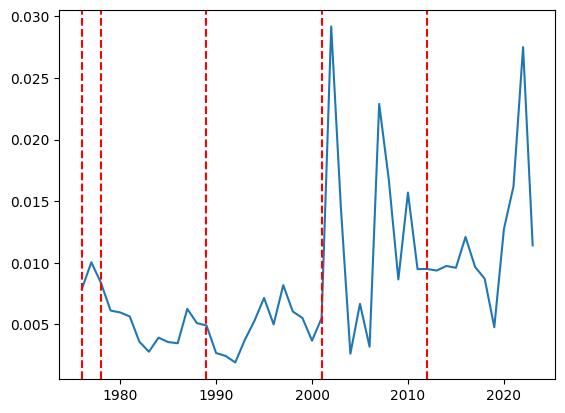

In [52]:
x = df_dist_yearly.query(f"(country == '{country}')").year_to[1:]
y = df_dist_yearly.query(f"(country == '{country}')").distance[1:]

plt.plot(x, y)
for year in change_year_list:
    plt.axvline(x=year, color='r', linestyle='--', label=f'Tipping Point: {year}')

In [1775]:
def get_kernel(df_dist):
    N = len(df_dist.index)
    D = df_dist.values
    D = (D + D.T) / 2
    np.fill_diagonal(D, 0)

    # 1. Переводим матрицу расстояний в матрицу сходства (Ядро)
    # Подберите медианное расстояние в качестве сигмы (gamma = 1 / (2 * sigma^2))
    gamma = 1.0 / (2 * (np.median(D) ** 2))
    K = np.exp(-gamma * (D ** 2))

    return K

def calculate_total_cost(cost_object, bkps, pen = 0):
    total_cost = 0
    start = 0
    for bkp in bkps:
        total_cost += cost_object.error(start, bkp)
        start = bkp
    return total_cost + pen * len(bkps)

def get_optimal_nbkp(algo, max_bkps, cutoff=0.5):
    n_bkps_range = range(1, max_bkps)
    costs = []
    for n_bkps in n_bkps_range:
        # Предсказываем фиксированное число точек
        bkps = algo.predict(n_bkps=n_bkps)
        
        # ИСПРАВЛЕНО: Считаем суммарную стоимость через интервальные ошибки bkps
        current_cost = calculate_total_cost(algo.cost, bkps)
        costs.append(current_cost)

    costs_diff = np.diff(np.array(costs))
    cost_indices = np.where(np.abs(costs_diff) < cutoff)[0]
    
    n_bkps_idx = 0 if len(cost_indices) == 0 else cost_indices[0]
    return n_bkps_range[n_bkps_idx] if n_bkps_idx != 0 else 0

def get_algo(df_dist, min_size=1):
    K = get_kernel(df_dist)

    w, V = np.linalg.eigh(K)
    w = np.clip(w, 0, None)                # clip small negative values
    X = V * np.sqrt(w) 

    algo = rpt.KernelCPD(kernel="linear", min_size=min_size).fit(X)
    return algo

def get_change_points(df_dist, min_size=1, cutoff=0.5, ):
    algo = get_algo(df_dist, min_size)
    max_bkps = int(np.floor(len(df_dist.index) / min_size))
    n_bkps = get_optimal_nbkp(algo, max_bkps, cutoff)
    if n_bkps == 0:
        return []
    years = df_dist.index.tolist()
    result_indices = algo.predict(n_bkps=n_bkps)
    detected_years = [years[idx] for idx in result_indices[:-1]]
    return detected_years

In [1619]:
import numpy as np

def chamfer_distance(A, B, squared=True):
    A = np.asarray(A)
    B = np.asarray(B)
    # print(A)
    distances = np.abs(A[:, None] - B[None, :])

    if squared:
        distances = distances ** 2

    return (
        distances.min(axis=1).mean()
        + distances.min(axis=0).mean()
    )

In [1621]:
def calculate_modularity(adjacency_matrix, partition):
    """
    Calculate modularity given an adjacency matrix and a partition.

    Parameters
    ----------
    adjacency_matrix : array-like, shape (n, n)
        Adjacency matrix of an undirected network.
    partition : array-like, shape (n,)
        Community label for each node.

    Returns
    -------
    float
        Modularity Q.
    """
    A = np.asarray(adjacency_matrix, dtype=float)
    partition = np.asarray(partition)

    degrees = A.sum(axis=1)
    m2 = A.sum()

    if m2 == 0:
        return 0.0

    # Expected edge weights under the configuration model
    expected = np.outer(degrees, degrees) / m2

    # Nodes in the same community
    same_community = partition[:, None] == partition[None, :]

    Q = np.sum((A - expected) * same_community) / m2

    return Q

In [1622]:
import numpy as np

def gini(x):
    x = np.asarray(x, dtype=float)

    if np.any(x < 0):
        raise ValueError("Gini requires non-negative values.")

    if len(x) == 0 or x.sum() == 0:
        return 0.0

    x = np.sort(x)
    n = len(x)

    return (2 * np.sum(np.arange(1, n + 1) * x)) / (n * x.sum()) - (n + 1) / n

In [1623]:
import numpy as np

def hoover(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan
    if np.any(x < 0):
        raise ValueError("Values must be non-negative.")
    if x.sum() == 0:
        return 0.0

    shares = x / x.sum()
    return 0.5 * np.abs(shares - 1 / len(x)).sum()

In [1624]:
import numpy as np

def entropy_inequality(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan
    if np.any(x < 0):
        raise ValueError("Values must be non-negative.")
    if x.sum() == 0:
        return 0.0
    if len(x) == 1:
        return 0.0

    p = x / x.sum()
    p = p[p > 0]

    entropy = -np.sum(p * np.log(p))

    return 1 - entropy / np.log(len(x))

import numpy as np

def coefficient_of_variation(x):
    x = np.asarray(x, dtype=float)

    if len(x) == 0:
        return np.nan

    mean = x.mean()

    if mean == 0:
        return 0.0 if np.all(x == 0) else np.nan

    return x.std(ddof=0) / mean

In [1786]:
def get_country_data(country, algo, year_list_active, K, D, n_bkps_range = None):

    if n_bkps_range is None:
        n_bkps_range = np.arange(len(year_list_active))[1:]

    bkps_prev = []
    df_list = []
    
    K_zero = K
    for i in range(K.shape[0]):
        K_zero[i, i] = 0
        
    for n_bkps in n_bkps_range:
    # Предсказываем фиксированное число точек
        bkps = algo.predict(n_bkps=n_bkps)
        bkps_year = np.array([year_list_active[0]] + [year_list_active[bkp] for bkp in bkps[:-1]] + [year_list_active[-1]])
        
        bkps_year_diff = np.diff(bkps_year)

        partition = np.zeros(K_zero.shape[0])
        val = 0
        prev_idx = 0
        for year in bkps_year[1:]:
            year_idx = year_list_active.index(year)
            partition[prev_idx:year_idx] = val
            val += 1
            prev_idx = year_idx

        if n_bkps == 1:
            bkps_prev = bkps_year
        else:
            # statistic, p_value = ks_2samp(sample_prev, sample)
            # print(bkps[:-1], bkps_prev[:-1], len([bkp for bkp in bkps_prev if bkp in bkps]), len(bkps_prev))
            # len([bkp for bkp in bkps_prev if bkp in bkps]) / len(bkps_prev)
            # intersect_prev = [bkp for bkp in bkps_prev[1:-1] if bkp in bkps_year[1:-1]]
            # union_prev = list(set(bkps[1:-1]).union(bkps_prev[1:-1]))
            # non_intersect_prev = [bkp for bkp in bkps[1:-1] if bkp not in bkps_prev[1:-1]]
            df_list.append({
                "country": country,
                "n_bkps": n_bkps,
                "n_bkps_prev": n_bkps - 1,
                "n_bkps_ratio": (n_bkps - 1) / len(year_list_active),
                #
                "chamfer_distance": chamfer_distance(bkps_prev[1:-1], bkps_year[1:-1]),
                # "jaccard": len(intersect_prev) / len(union_prev),
                # for previous n_bkps
                "gini_period": gini(np.diff(bkps_prev)),
                "hoover_period": hoover(np.diff(bkps_prev)),
                "norm_entropy": entropy_inequality(np.diff(bkps_prev)),
                "variation_coef": coefficient_of_variation(np.diff(bkps_prev)),
                # for previous n_bkps
                "period_max": max(np.diff(bkps_prev)),
                "max_period": np.max(np.diff(bkps_prev)),
                "min_period": np.min(np.diff(bkps_prev)),
                "median_period": np.median(np.diff(bkps_prev)),
                # for previous n_bkps
                "silhouette": silhouette_score(D, partition, metric="precomputed"),
                "modularity": calculate_modularity(K_zero, partition),
                # 
                "cost": algo.cost.sum_of_costs(bkps),
                # "bkps": bkps_prev
            })
            bkps_prev = bkps_year
    return pd.json_normalize(df_list)


In [1868]:
country = "RU"
df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
df_dist_test = df_dist_test.loc[year_list_active, year_list_active]
K = get_kernel(df_dist_test)
algo = get_algo(df_dist_test)
df_country_data = get_country_data(country, algo, year_list_active, K, df_dist_test.fillna(0).values)

In [1869]:
(
    df_country_data
    .query("chamfer_distance < 2")
    # .query("dissimilarity_ratio < scale")
    .assign(
        bkps_dist = lambda df: [df.n_bkps.iloc[0]] + df.n_bkps.diff().to_list()[1:]
    )
    .query("bkps_dist > 1")
)

,country,n_bkps,n_bkps_prev,n_bkps_ratio,chamfer_distance,gini_period,hoover_period,norm_entropy,variation_coef,period_max,max_period,min_period,median_period,silhouette,modularity,cost,bkps_dist
3,RU,5,4,0.08,1.100000,0.424490,0.395918,0.212415,0.814794,20,20,2,5.0,0.476320,0.107141,2.76897,5.0
5,RU,7,6,0.12,0.880952,0.437318,0.387755,0.176584,0.870642,17,17,2,4.0,0.256952,0.084270,1.96890,2.0
9,RU,11,10,0.20,0.090909,0.319109,0.259740,0.069314,0.592891,10,10,2,3.0,0.237124,0.029304,1.09613,4.0


In [1870]:
px.line(df_country_data.assign(score=lambda df: np.abs(df.silhouette.diff()) / df.silhouette.shift(1)), "n_bkps_prev", "cost")

In [1812]:
country_list = list(df_dist_year.reset_index().country.unique())

In [1813]:
df_list = []

for country in country_list:
    df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
    year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
    if len(year_list_active) <= 20:
        continue
    df_dist_test = df_dist_test.loc[year_list_active, year_list_active]
    K = get_kernel(df_dist_test)
    algo = get_algo(df_dist_test)
    df_country_data = get_country_data(country, algo, year_list_active, K, df_dist_test.fillna(0).values)

    df_list.append(
        df_country_data
        .query("chamfer_distance < 2")
        # .query("dissimilarity_ratio < scale")
        .assign(
            bkps_dist = lambda df: [df.n_bkps.iloc[0]] + df.n_bkps.diff().to_list()[1:]
        )
        .query("bkps_dist > 1")
    )

df_n_bkps = (
    pd.concat(df_list)
    # .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
    # .drop("country", axis=1)
    # .rename(columns={"alpha-3": "country"})
)

In [1818]:
var = "silhouette"

# country_group = ["alpha2", "name", "region", "sub-region"]

df_plot = (
    df_n_bkps
    .groupby(["country"], as_index=False)[var].min()
    .assign(n_divisions=df_n_bkps.groupby(["country"], as_index=False)[var].count()[var].to_list())
    .merge(df_n_bkps, on=["country", var])
    .merge(df_country[["alpha2", "alpha-3", "name", "region", "sub-region"]], left_on="country", right_on="alpha2")
    .drop("country", axis=1)
    .rename(columns={"alpha-3": "country"})
    # .query("modularity >= 0")
    
)

# display(df_plot)

fig = px.choropleth(
    df_plot,
    locations="country",
    # locationmode="country names",
    color="gini_period",
    hover_name="country",
    hover_data=["alpha2", "n_bkps_ratio", "n_bkps_prev", "gini_period", "silhouette", "min_period", "max_period", "median_period"],
    color_continuous_scale="Viridis",
    projection="natural earth",
)
fig.show()

In [1747]:
df_plot[["gini_period", "silhouette", "n_divisions", "max_period"]].corr()

,gini_period,silhouette,n_divisions,max_period
gini_period,1.000000,0.198002,0.349577,0.610616
silhouette,0.198002,1.000000,0.301623,0.516154
n_divisions,0.349577,0.301623,1.000000,0.722186
max_period,0.610616,0.516154,0.722186,1.000000


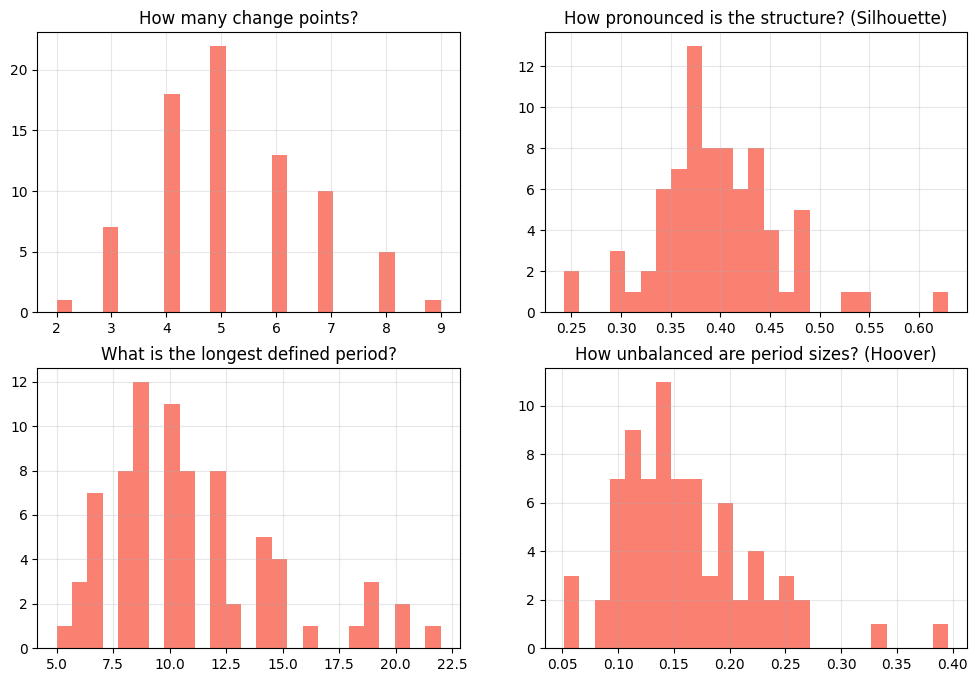

In [1774]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(12, 8))
ax2.hist(df_plot.silhouette, bins=25, color="salmon")
ax2.grid(alpha=0.3)
ax2.set_title("How pronounced is the structure? (Silhouette)")

ax4.hist(df_plot.hoover_period, bins=25, color="salmon")
ax4.grid(alpha=0.3)
ax4.set_title("How unbalanced are period sizes? (Hoover)")

ax1.hist(df_plot.n_bkps_prev, bins=25, color="salmon")
ax1.grid(alpha=0.3)
ax1.set_title("How many change points?")

ax3.hist(df_plot.max_period, bins=25, color="salmon")
ax3.grid(alpha=0.3)
ax3.set_title("What is the longest defined period?")

plt.show()

In [1640]:
country_list_test = ["RU", "US", "RO"]
df_plot.query("alpha2 in @country_list_test")[["alpha2", "n_bkps", "n_bkps_prev", "gini_period", "hoover_period", "max_period", "min_period", "bkps"]]

,alpha2,n_bkps,n_bkps_prev,gini_period,hoover_period,max_period,min_period,bkps
59,RO,5,4,0.272727,0.218182,15,4,"[1979, 1994, 2006, 2010, 2014, 2023]"
61,RU,5,4,0.424490,0.395918,20,2,"[1974, 1994, 2013, 2016, 2021, 2023]"
72,US,8,7,0.196429,0.135204,9,2,"[1974, 1978, 1987, 1996, 2002, 2008, 2014, 202..."


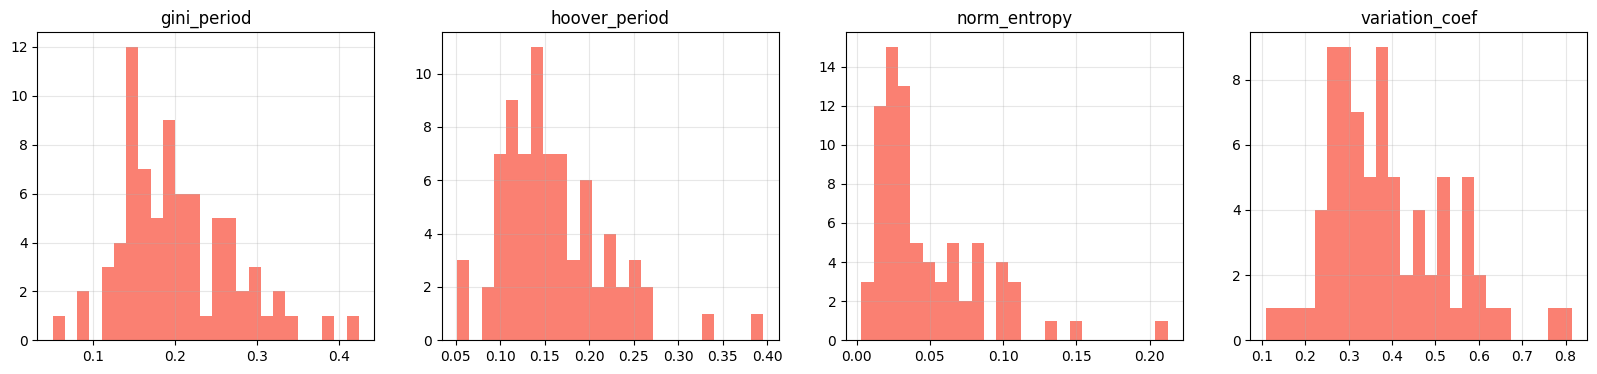

In [1641]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 4))
ax1.hist(df_plot.gini_period, bins=25, color="salmon")
ax1.grid(alpha=0.3)
ax1.set_title("gini_period")

ax2.hist(df_plot.hoover_period, bins=25, color="salmon")
ax2.grid(alpha=0.3)
ax2.set_title("hoover_period")

ax3.hist(df_plot.norm_entropy, bins=25, color="salmon")
ax3.grid(alpha=0.3)
ax3.set_title("norm_entropy")

ax4.hist(df_plot.variation_coef, bins=25, color="salmon")
ax4.grid(alpha=0.3)
ax4.set_title("variation_coef")

plt.show()

In [1643]:
df_plot[["gini_period", "hoover_period", "norm_entropy", "variation_coef"]].corr()

,gini_period,hoover_period,norm_entropy,variation_coef
gini_period,1.000000,0.968659,0.950361,0.976696
hoover_period,0.968659,1.000000,0.952128,0.952788
norm_entropy,0.950361,0.952128,1.000000,0.935744
variation_coef,0.976696,0.952788,0.935744,1.000000


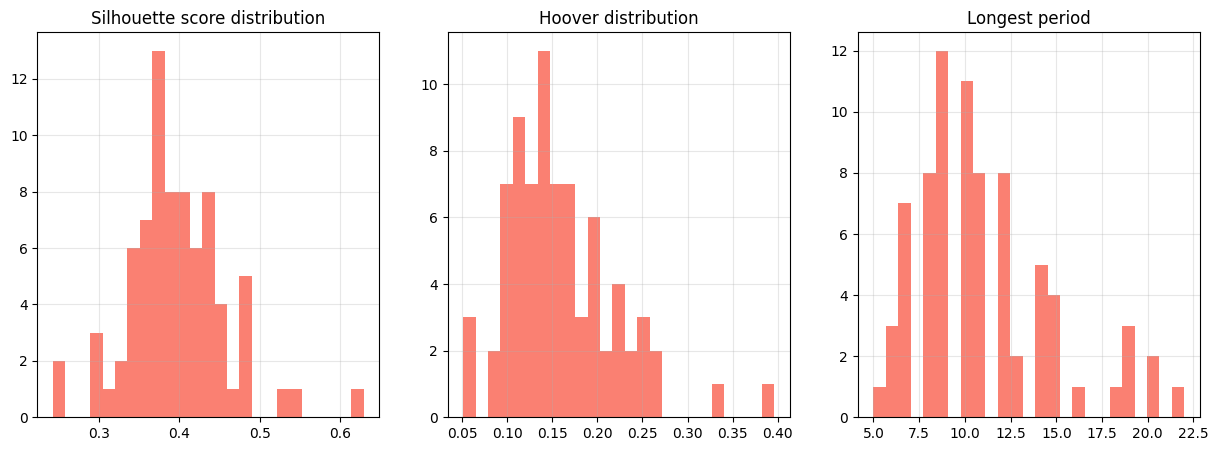

In [1678]:
df_plot[["gini_period", "silhouette", "hoover_period"]].corr()

,gini_period,silhouette,hoover_period
gini_period,1.000000,0.198002,0.968659
silhouette,0.198002,1.000000,0.221128
hoover_period,0.968659,0.221128,1.000000


In [1757]:
px.scatter(df_plot.sort_values(["region", "sub-region"]), x="sub-region", y="max_period", hover_data=["name", "alpha2"], color="silhouette")

In [1762]:
px.scatter(df_plot, x="silhouette", y="gini_period", hover_data=["alpha2", "name"], color="sub-region")

# One country

In [1871]:
country = "UA"
min_size = 1
n_bkps = int(df_plot.query("alpha2 == @country").n_bkps_prev.values[0])

df_dist_test = df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance")
year_list_active = df_cs.xs((country, mode), level=(0, 2)).sum(axis=1).to_frame("total").query("total >= 500").index.to_list()
df_dist_test = df_dist_test.loc[year_list_active, year_list_active]

In [1872]:
N = len(df_dist_test.index)
D = df_dist_test.values
np.fill_diagonal(D, 0)

d = D[np.triu_indices_from(D, k=1)]
gamma = 1.0 / (2 * (np.median(d) ** 2))
K = np.exp(-gamma * (D ** 2))

w, V = np.linalg.eigh(K)
w = np.clip(w, 0, None)                # clip small negative values
X = V * np.sqrt(w) 

algo = rpt.KernelCPD(kernel="linear", min_size=min_size).fit(X)

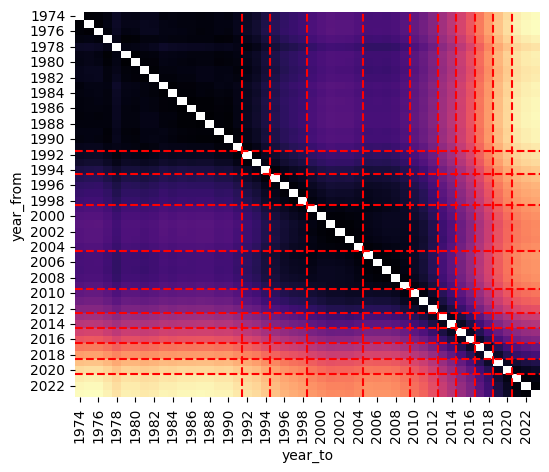

In [1873]:
fig, ax = plt.subplots(figsize=(6, 5))

result_indices = algo.predict(n_bkps=n_bkps)
detected_years = [year_list_active[idx] for idx in result_indices[:-1]]
detected_years_full = [year_list_active[0]] + detected_years + [year_list_active[-1]]


sns.heatmap(
    df_dist_year.xs((country, "individual"), level=(0, 1)).pivot(columns="year_to", values="distance").loc[year_list_active, year_list_active],
    ax=ax, cbar=False, cmap="magma",
)

# df_K = pd.DataFrame(K, index=year_list_active, columns=year_list_active)
# sns.heatmap(
#     df_K,
#     ax=ax, cbar=False, cmap="magma",
# )
for year in detected_years:
    if year not in year_list_active:
        continue
    i = year_list_active.index(year)
    ax.axvline(x=i, color='red', linestyle='--', label=f'Tipping Point: {year}')
    ax.axhline(y=i, color='r', linestyle='--', label=f'Tipping Point: {year}')


In [1841]:
def calculate_total_cost(cost_object, bkps):
    """Вспомогательная функция для расчета полной стоимости разбиения"""
    total_cost = 0
    start = 0
    for bkp in bkps:
        total_cost += cost_object.error(start, bkp)
        start = bkp
    return total_cost

# 1. Считаем ошибку разбиения для РЕАЛЬНЫХ данных
real_bkps = algo.predict(n_bkps=n_bkps)
real_cost = calculate_total_cost(algo.cost, real_bkps)

# 2. Запускаем симуляцию (перемешиваем данные 200 раз)
n_permutations = 200  
permuted_costs = []

for i in range(n_permutations):
    # Случайно перемешиваем индексы лет
    perm_indices = np.random.permutation(N)
    # Пересобираем матрицу сходства K в случайном порядке
    K_perm = K[perm_indices, :][:, perm_indices]
    
    # Обучаем алгоритм на случайной матрице
    algo_perm = rpt.KernelCPD(kernel="linear", min_size=min_size).fit(K_perm)
    bkps_perm = algo_perm.predict(n_bkps=n_bkps)
    
    # Считаем стоимость для перемешанной матрицы
    perm_cost = calculate_total_cost(algo_perm.cost, bkps_perm)
    permuted_costs.append(perm_cost)

# 3. Считаем P-value
p_value = np.sum(np.array(permuted_costs) <= real_cost) / n_permutations

print(f"Реальная стоимость разбиения: {real_cost:.4f}")
print(f"Средняя стоимость на случайных данных: {np.mean(permuted_costs):.4f}")
print(f"Полученный P-value: {p_value:.8f}")

if p_value < 0.05:
    print("✨ Смысл есть! Временная структура ваших данных статистически значима (p < 0.05).")
else:
    print("❌ Смысла нет. Случайно перемешанные годы делятся на периоды с такой же или меньшей ошибкой.")


Реальная стоимость разбиения: 2.8765
Средняя стоимость на случайных данных: 136.3405
Полученный P-value: 0.00000000
✨ Смысл есть! Временная структура ваших данных статистически значима (p < 0.05).


<BarContainer object of 8 artists>

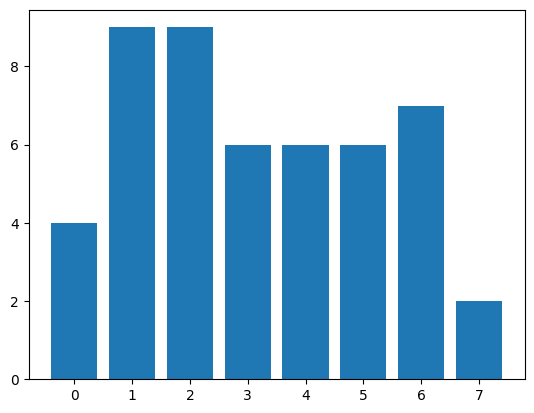

In [1842]:

plt.bar(np.arange(len(np.diff(detected_years_full))), np.diff(detected_years_full))

In [1843]:
K_zero = K

for i in range(K.shape[0]):
    K_zero[i, i] = 0


In [1844]:
detected_years+[year_list_active[-1]]

[1978, 1987, 1996, 2002, 2008, 2014, 2021, 2023]

In [1845]:
partition = np.zeros(K_zero.shape[0])
val = 0
prev_idx = 0
for year in detected_years+[year_list_active[-1]]:
    year_idx = year_list_active.index(year)
    partition[prev_idx:year_idx] = val
    val += 1
    prev_idx = year_idx
partition

array([0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2., 2., 2., 2.,
       2., 2., 2., 2., 2., 3., 3., 3., 3., 3., 3., 4., 4., 4., 4., 4., 4.,
       5., 5., 5., 5., 5., 5., 6., 6., 6., 6., 6., 6., 6., 7., 7., 0.])

In [1846]:
Q = calculate_modularity(K_zero, partition)

In [1847]:
Q

np.float64(0.050738562049465336)

In [1848]:
detected_years

[1978, 1987, 1996, 2002, 2008, 2014, 2021]

In [1849]:
detected_years_full = [year_list_active[0]] + detected_years + [year_list_active[-1]]
n_periods = len(detected_years_full)-1

period_distances = np.full((n_periods, n_periods), np.nan)

prev_year = year_list_active[0]
for i, year_from in enumerate(detected_years_full[:-1]):
    for j, year_to in enumerate(detected_years_full[:-1]):
        if j < i:
            continue
        period_distances[j, i] = period_distances[i, j] = df_dist_test.loc[year_from : detected_years_full[i+1], year_to : detected_years_full[j+1]].mean().mean()

df_period_distance = pd.DataFrame(period_distances, index=detected_years_full[:-1], columns=detected_years_full[:-1])

In [1850]:
n_periods = (len(detected_years_full) - 1)
gini(np.diff(np.array(detected_years_full)))


np.float64(0.1964285714285714)

<Axes: >

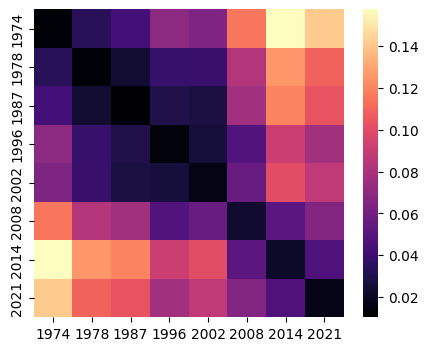

In [1851]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.heatmap(
    df_period_distance,
    ax=ax, cbar=True, cmap="magma",
)